# Assignment 5: Machine learning for clinical time series data

**Course:** ML for Health (CMU) · **Due:** Nov 24  
**Goal:** Fetal hypoxia / acidosis detection from the CTU-UHB CTG dataset using **cord pH < 7.20** as the cutoff.

This notebook answers each assignment question and sub-question in its own section. Supporting code lives in `src/`.

**Dataset:** 552 FHR + UC recordings (≤90 min, 4 Hz) ending at delivery, with cord gases, Apgar scores, and maternal/fetal metadata ([PhysioNet CTU-UHB](https://physionet.org/content/ctu-uhb-ctgdb/1.0.0/)).

## 0. Setup

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if (ROOT / 'src').exists():
    pass
elif (ROOT.parent / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    DATA_DIR, FIGURES_DIR, RESULTS_DIR, DEMOGRAPHIC_COLS,
    FS, PH_CUTOFF, PH_SEVERE, QUALITY_MISSING_MAX, SHORT_GAP_SEC,
)
from src.data_loader import load_metadata_table, load_all_signals
from src.preprocess import (
    prepare_signal, missing_fraction, interpolate_short_gaps,
    cohort_missingness_table, apply_quality_filter,
)
from src.features import segment_events, build_feature_table, extract_window_features
from src.classify import evaluate_setting

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

print("Data dir:", DATA_DIR)
assert DATA_DIR.exists(), "CTU-UHB data not found"

Data dir: /Users/eugeneho/Desktop/assignment_5/data/ctu-uhb


In [2]:
meta = load_metadata_table()
print(f"Loaded metadata for {len(meta)} records")
display(meta.head())

print("Loading signals...")
signals = load_all_signals()
print(f"Loaded {len(signals)} FHR/UC pairs")

Loaded metadata for 552 records


,pH,BDecf,pCO2,BE,Apgar1,Apgar5,Gest_weeks,Weight_g,Sex,Age,...,Rec_type,Pos_II_st,Sig2Birth,dbID,record_id,n_samples,duration_min,hypoxia_7_20,hypoxia_7_05,rec_type_label
0,7.14,8.14,7.7,-10.5,6.0,8.0,37.0,2660.0,2.0,32.0,...,1.0,14400.0,0.0,974204.0,1001,19200,80.0,1,0,Doppler ultrasound
1,7.00,7.92,12.0,-12.0,8.0,8.0,41.0,2900.0,2.0,23.0,...,1.0,14400.0,0.0,975666.0,1002,19200,80.0,1,1,Doppler ultrasound
2,7.20,3.03,8.3,-5.6,7.0,9.0,40.0,3770.0,1.0,31.0,...,1.0,14400.0,0.0,982315.0,1003,18000,75.0,0,0,Doppler ultrasound
3,7.30,5.19,5.5,-6.4,8.0,9.0,41.0,3370.0,1.0,36.0,...,12.0,14400.0,0.0,983277.0,1004,16800,70.0,0,0,Combined US + fECG
4,7.30,4.52,5.7,-5.8,9.0,10.0,41.0,3550.0,2.0,28.0,...,1.0,14400.0,0.0,983398.0,1005,18000,75.0,0,0,Doppler ultrasound


Loading signals...


Loaded 552 FHR/UC pairs


---
## 1. Dataset exploration

Understand what is in the dataset: which variables are present, and what they mean.

In [3]:
variable_guide = pd.DataFrame([
    ("FHR", "Fetal heart rate time series (bpm), sampled at 4 Hz"),
    ("UC", "Uterine contraction / toco signal, sampled at 4 Hz"),
    ("pH", "Umbilical artery cord blood pH (objective hypoxia label)"),
    ("BDecf / BE / pCO2", "Acid-base / gas exchange outcomes"),
    ("Apgar1 / Apgar5", "Clinician-assigned newborn scores at 1 and 5 min"),
    ("Gest_weeks, Weight_g, Sex", "Fetal / neonatal descriptors"),
    ("Age, Gravidity, Parity", "Maternal demographics"),
    ("Diabetes, Hypertension, Preeclampsia, ...", "Maternal risk factors"),
    ("Induced, Deliv_type, I_stage, II_stage", "Delivery descriptors"),
    ("Rec_type", "Acquisition: 1=Doppler US, 2=fECG scalp, 12=combined"),
], columns=["Variable", "Meaning"])
display(variable_guide)

print(f"Outcome label: hypoxia = 1{{pH < {PH_CUTOFF}}}")
print(meta[["pH", "hypoxia_7_20", "Apgar1", "Rec_type", "Age", "Weight_g"]].describe().round(3))

,Variable,Meaning
0,FHR,"Fetal heart rate time series (bpm), sampled at..."
1,UC,"Uterine contraction / toco signal, sampled at ..."
2,pH,Umbilical artery cord blood pH (objective hypo...
3,BDecf / BE / pCO2,Acid-base / gas exchange outcomes
4,Apgar1 / Apgar5,Clinician-assigned newborn scores at 1 and 5 min
5,"Gest_weeks, Weight_g, Sex",Fetal / neonatal descriptors
6,"Age, Gravidity, Parity",Maternal demographics
7,"Diabetes, Hypertension, Preeclampsia, ...",Maternal risk factors
8,"Induced, Deliv_type, I_stage, II_stage",Delivery descriptors
9,Rec_type,"Acquisition: 1=Doppler US, 2=fECG scalp, 12=co..."


Outcome label: hypoxia = 1{pH < 7.2}
            pH  hypoxia_7_20   Apgar1  Rec_type      Age  Weight_g
count  552.000       552.000  552.000   552.000  552.000   551.000
mean     7.230         0.321    8.263     1.875   29.674  3400.426
std      0.105         0.467    1.625     2.668    4.539   454.782
min      6.850         0.000    1.000    -1.000   18.000  1970.000
25%      7.170         0.000    8.000     1.000   27.000  3100.000
50%      7.250         0.000    9.000     1.000   30.000  3410.000
75%      7.300         1.000    9.000     1.000   33.000  3700.000
max      7.470         1.000   10.000    12.000   46.000  4750.000


### 1a. Plot examples of one normal and one hypoxic trace — what do you notice?

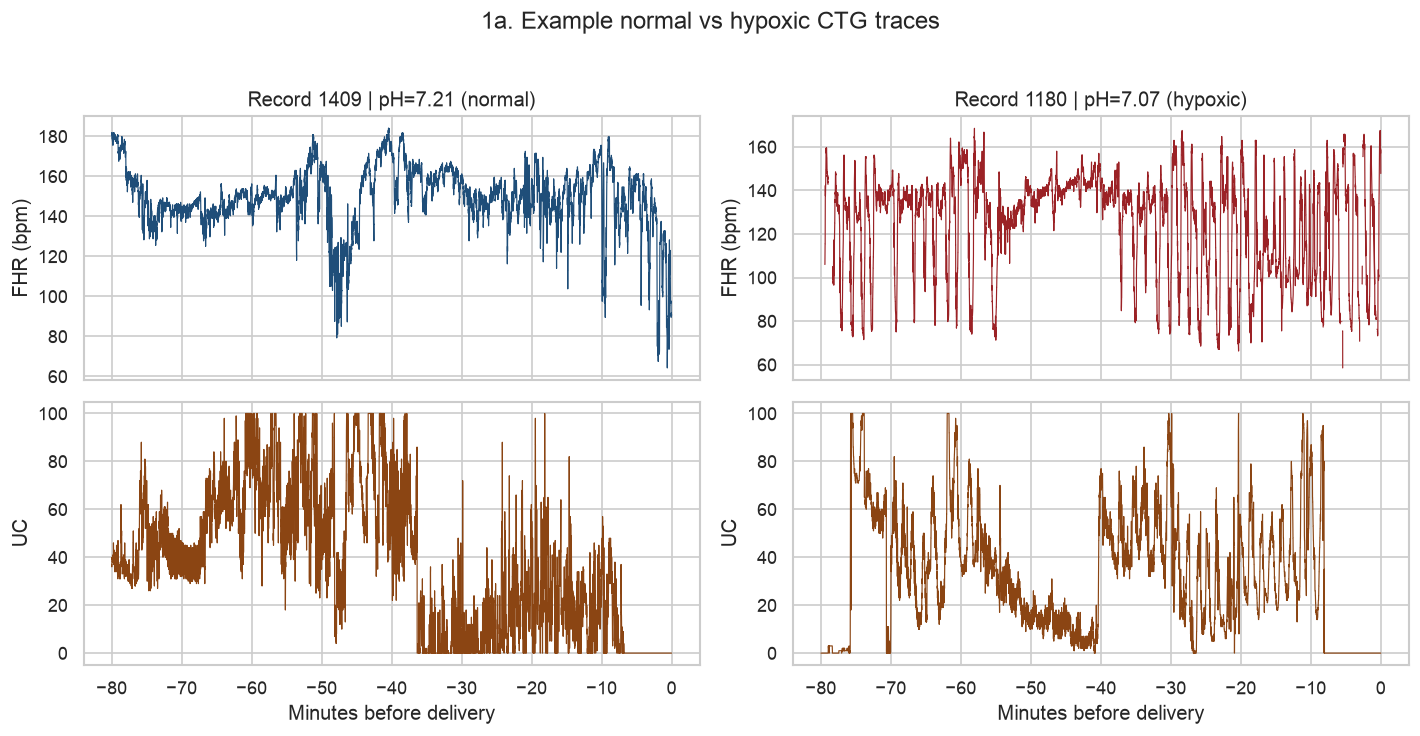

Normal example: 1409 | Hypoxic example: 1180
What we notice:
- Both traces show intermittent dropouts (zeros / gaps), more visible as labor progresses.
- The hypoxic example often shows more late/deep decelerations, lower variability, and
  a less stable baseline near delivery — but visual CTG patterns are imperfect proxies for pH.
- UC activity typically increases toward delivery; FHR responses to contractions matter clinically.



In [4]:
miss_proxy = {rid: np.mean(~np.isfinite(signals[rid]["fhr"])) for rid in signals}
normals = meta.loc[meta["hypoxia_7_20"] == 0].assign(miss=lambda d: d["record_id"].map(miss_proxy))
hyps = meta.loc[meta["hypoxia_7_20"] == 1].assign(miss=lambda d: d["record_id"].map(miss_proxy))
rid_n = normals.sort_values("miss").iloc[0]["record_id"]
severe = hyps.loc[hyps["pH"] < 7.10].sort_values("miss")
rid_h = severe.iloc[0]["record_id"] if len(severe) else hyps.sort_values("miss").iloc[0]["record_id"]

def plot_ctg(rid, ax_fhr, ax_uc, color_fhr):
    fhr, uc = signals[rid]["fhr"], signals[rid]["uc"]
    t = np.arange(len(fhr)) / FS / 60.0
    t = t - t[-1]
    ax_fhr.plot(t, fhr, color=color_fhr, lw=0.7)
    ax_uc.plot(t, uc, color="#8b4513", lw=0.7)
    ph = meta.set_index("record_id").loc[rid, "pH"]
    ax_fhr.set_title(f"Record {rid} | pH={ph:.2f}")
    ax_fhr.set_ylabel("FHR (bpm)")
    ax_uc.set_ylabel("UC")
    ax_uc.set_xlabel("Minutes before delivery")

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex="col")
plot_ctg(rid_n, axes[0, 0], axes[1, 0], "#1f4e79")
plot_ctg(rid_h, axes[0, 1], axes[1, 1], "#9b2226")
axes[0, 0].set_title(axes[0, 0].get_title() + " (normal)")
axes[0, 1].set_title(axes[0, 1].get_title() + " (hypoxic)")
fig.suptitle("1a. Example normal vs hypoxic CTG traces", y=1.02)
fig.tight_layout()
plt.show()

print(f"Normal example: {rid_n} | Hypoxic example: {rid_h}")
print('''What we notice:
- Both traces show intermittent dropouts (zeros / gaps), more visible as labor progresses.
- The hypoxic example often shows more late/deep decelerations, lower variability, and
  a less stable baseline near delivery — but visual CTG patterns are imperfect proxies for pH.
- UC activity typically increases toward delivery; FHR responses to contractions matter clinically.
''')

### 1b. Plot the distribution of cord pH. Report positive rates at pH < 7.20 and pH < 7.05. How might we address imbalance?

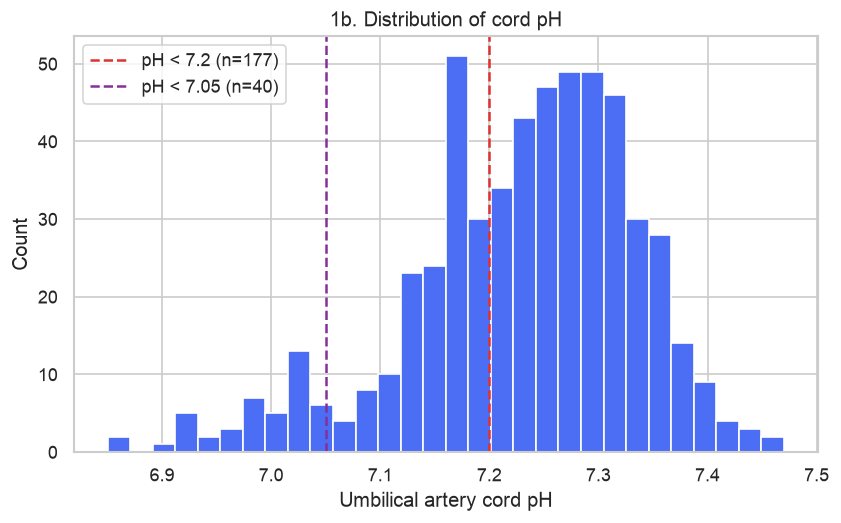

Positive rate pH < 7.20: 177/552 = 32.1%
Positive rate pH < 7.05: 40/552 = 7.2%
Addressing imbalance:
1. class_weight='balanced' (or sample weights) in the classifier
2. Oversample minority / undersample majority within CV folds only
3. Threshold tuning on ROC (e.g. fix specificity ~0.90, report sensitivity)
4. Report AUC + clinically meaningful operating points rather than accuracy alone
5. Optionally train on a rarer severe cutoff (pH<7.05) with stronger rebalancing



In [5]:
n = len(meta)
n720 = int((meta["pH"] < PH_CUTOFF).sum())
n705 = int((meta["pH"] < PH_SEVERE).sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(meta["pH"], bins=30, color="#4c6ef5", edgecolor="white")
ax.axvline(PH_CUTOFF, color="#e03131", ls="--", label=f"pH < {PH_CUTOFF} (n={n720})")
ax.axvline(PH_SEVERE, color="#862e9c", ls="--", label=f"pH < {PH_SEVERE} (n={n705})")
ax.set_xlabel("Umbilical artery cord pH")
ax.set_ylabel("Count")
ax.set_title("1b. Distribution of cord pH")
ax.legend()
plt.show()

print(f"Positive rate pH < 7.20: {n720}/{n} = {n720/n:.1%}")
print(f"Positive rate pH < 7.05: {n705}/{n} = {n705/n:.1%}")
print('''Addressing imbalance:
1. class_weight='balanced' (or sample weights) in the classifier
2. Oversample minority / undersample majority within CV folds only
3. Threshold tuning on ROC (e.g. fix specificity ~0.90, report sensitivity)
4. Report AUC + clinically meaningful operating points rather than accuracy alone
5. Optionally train on a rarer severe cutoff (pH<7.05) with stronger rebalancing
''')

### 1c. Plot the distribution of data acquisition methods (external Doppler ultrasound vs fECG)

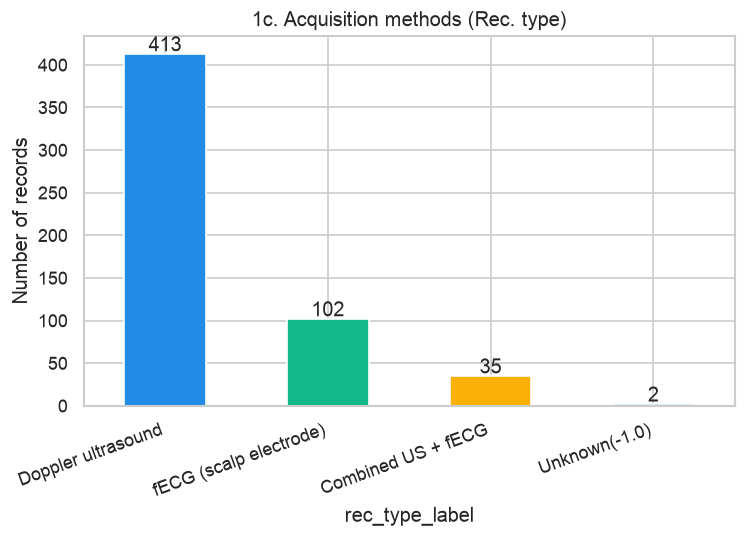

,n
rec_type_label,
Doppler ultrasound,413
fECG (scalp electrode),102
Combined US + fECG,35
Unknown(-1.0),2


Rec. type codes: 1 = Doppler ultrasound, 2 = direct scalp fECG, 12 = combined.


In [6]:
counts = meta["rec_type_label"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", ax=ax, color=["#228be6", "#12b886", "#fab005"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha="center")
ax.set_ylabel("Number of records")
ax.set_title("1c. Acquisition methods (Rec. type)")
plt.xticks(rotation=20, ha="right")
plt.show()
display(counts.to_frame("n"))
print("Rec. type codes: 1 = Doppler ultrasound, 2 = direct scalp fECG, 12 = combined.")

### 1d. Plot correlations between demographic variables and cord pH

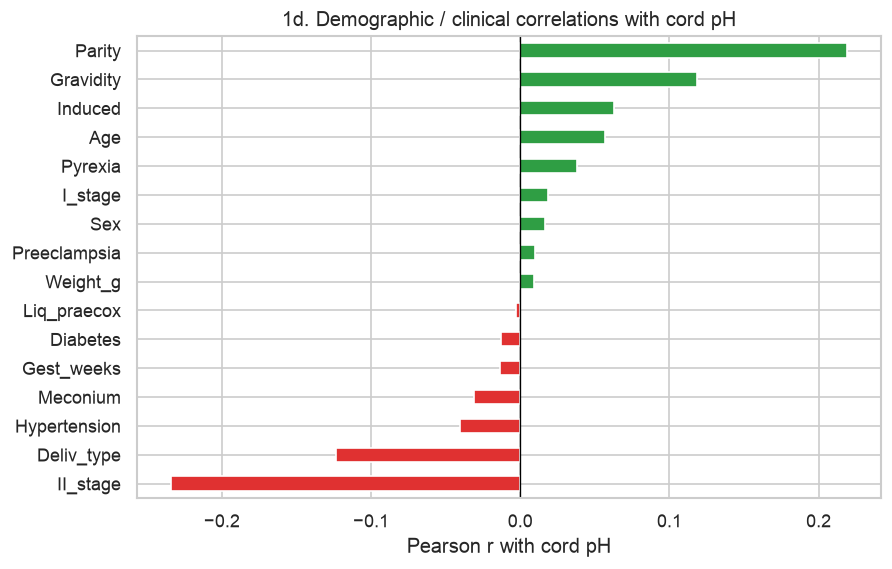

Stronger |r| suggests association with acidosis risk (not necessarily causal).
II_stage       -0.234
Deliv_type     -0.124
Hypertension   -0.040
Meconium       -0.031
Gest_weeks     -0.014
Diabetes       -0.013
Liq_praecox    -0.003
Weight_g        0.009
Preeclampsia    0.010
Sex             0.017
I_stage         0.019
Pyrexia         0.038
Age             0.057
Induced         0.063
Gravidity       0.119
Parity          0.219


In [7]:
demo_cols = [c for c in DEMOGRAPHIC_COLS if c in meta.columns]
corr = meta[demo_cols + ["pH"]].corr(numeric_only=True)["pH"].drop("pH").sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#e03131" if v < 0 else "#2f9e44" for v in corr.values]
corr.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson r with cord pH")
ax.set_title("1d. Demographic / clinical correlations with cord pH")
plt.show()

print("Stronger |r| suggests association with acidosis risk (not necessarily causal).")
print(corr.round(3).to_string())

---
## 2. Signal missingness

Signal dropout is common in intrapartum CTG. Per the assignment: gaps **< 10 s** are linearly interpolated; gaps **≥ 10 s** remain missing / logged as missing segments. The reference figure also shows validity masks and fill+smooth preprocessing.

### 2a. Distribution of missingness — by hypoxia status and by acquisition method

,fhr_missing,uc_missing,hypoxia_7_20
count,552.000000,552.0,552.000000
mean,0.152182,0.0,0.320652
std,0.118354,0.0,0.467151
min,0.000000,0.0,0.000000
25%,0.050769,0.0,0.000000
50%,0.138555,0.0,0.000000
75%,0.227437,0.0,1.000000
max,0.518975,0.0,1.000000


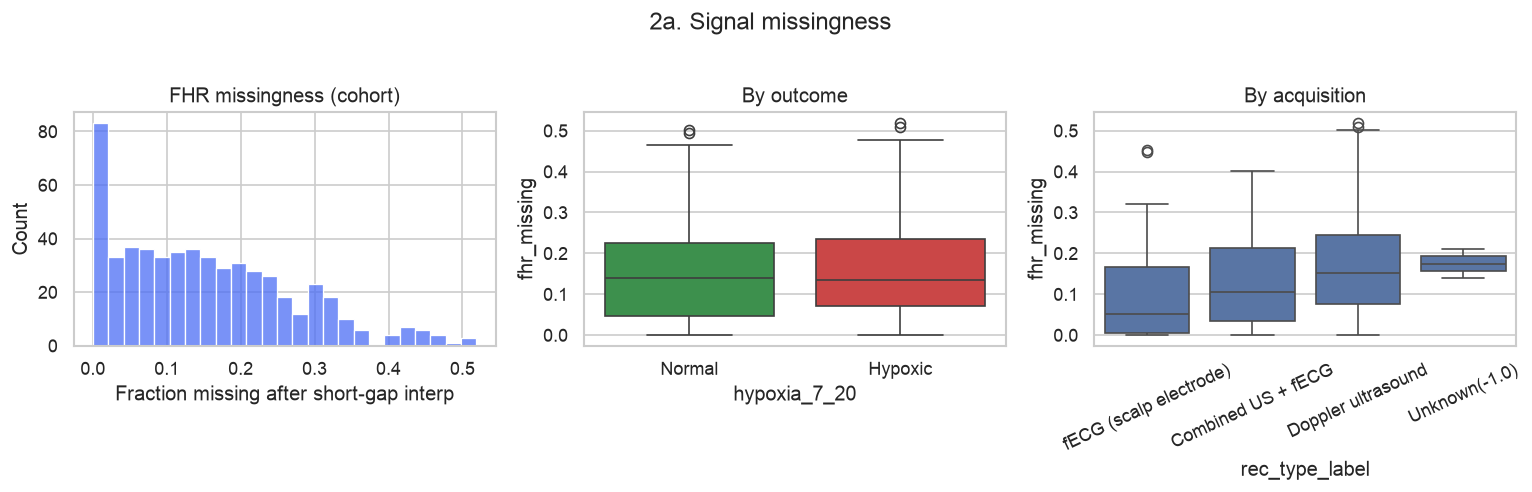

Mean FHR missing — normal: 0.146
Mean FHR missing — hypoxic: 0.165
                         mean  median  count
rec_type_label                              
Combined US + fECG      0.139   0.106     35
Doppler ultrasound      0.168   0.151    413
Unknown(-1.0)           0.175   0.175      2
fECG (scalp electrode)  0.093   0.051    102
Interpretation:
- External Doppler ultrasound typically has more dropout than direct scalp fECG.
- Missingness differences by hypoxia status are usually modest; acquisition method is a bigger driver.



In [8]:
miss = cohort_missingness_table(signals, meta)
display(miss[["fhr_missing", "uc_missing", "hypoxia_7_20", "rec_type_label"]].describe())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sns.histplot(miss["fhr_missing"], bins=25, ax=axes[0], color="#4c6ef5")
axes[0].set_title("FHR missingness (cohort)")
axes[0].set_xlabel("Fraction missing after short-gap interp")

sns.boxplot(data=miss, x="hypoxia_7_20", y="fhr_missing", ax=axes[1],
            palette=["#2f9e44", "#e03131"])
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Normal", "Hypoxic"])
axes[1].set_title("By outcome")

order = miss.groupby("rec_type_label")["fhr_missing"].median().sort_values().index
sns.boxplot(data=miss, x="rec_type_label", y="fhr_missing", ax=axes[2], order=order)
axes[2].set_title("By acquisition")
axes[2].tick_params(axis="x", rotation=25)
fig.suptitle("2a. Signal missingness", y=1.02)
fig.tight_layout()
plt.show()

print("Mean FHR missing — normal:", round(miss.loc[miss.hypoxia_7_20==0, "fhr_missing"].mean(), 3))
print("Mean FHR missing — hypoxic:", round(miss.loc[miss.hypoxia_7_20==1, "fhr_missing"].mean(), 3))
print(miss.groupby("rec_type_label")["fhr_missing"].agg(["mean","median","count"]).round(3))
print('''Interpretation:
- External Doppler ultrasound typically has more dropout than direct scalp fECG.
- Missingness differences by hypoxia status are usually modest; acquisition method is a bigger driver.
''')

### 2b. 10% missingness quality filter — impact on N, class balance, and acquisition mix

In [9]:
kept = apply_quality_filter(miss, max_missing=QUALITY_MISSING_MAX, channel="fhr_missing")
summary_2b = pd.DataFrame({
    "n_records": [len(miss), len(kept)],
    "pos_rate_pH<7.20": [miss["hypoxia_7_20"].mean(), kept["hypoxia_7_20"].mean()],
}, index=["before_filter", "after_<=10%_missing"])
display(summary_2b.round(3))

print("Acquisition counts before vs after filter:")
display(pd.concat([
    miss["rec_type_label"].value_counts().rename("before"),
    kept["rec_type_label"].value_counts().rename("after"),
], axis=1).fillna(0).astype(int))

print(f'''Effect of <={QUALITY_MISSING_MAX:.0%} FHR-missing filter:
- Usable N drops substantially ({len(miss)} -> {len(kept)}).
- Class balance and acquisition mix can shift because noisier US traces are preferentially removed.
- Higher-quality fECG traces are more likely to survive the filter.
''')

,n_records,pos_rate_pH<7.20
before_filter,552,0.321
after_<=10%_missing,216,0.315


Acquisition counts before vs after filter:


,before,after
rec_type_label,,
Doppler ultrasound,413,139
fECG (scalp electrode),102,61
Combined US + fECG,35,16
Unknown(-1.0),2,0


Effect of <=10% FHR-missing filter:
- Usable N drops substantially (552 -> 216).
- Class balance and acquisition mix can shift because noisier US traces are preferentially removed.
- Higher-quality fECG traces are more likely to survive the filter.



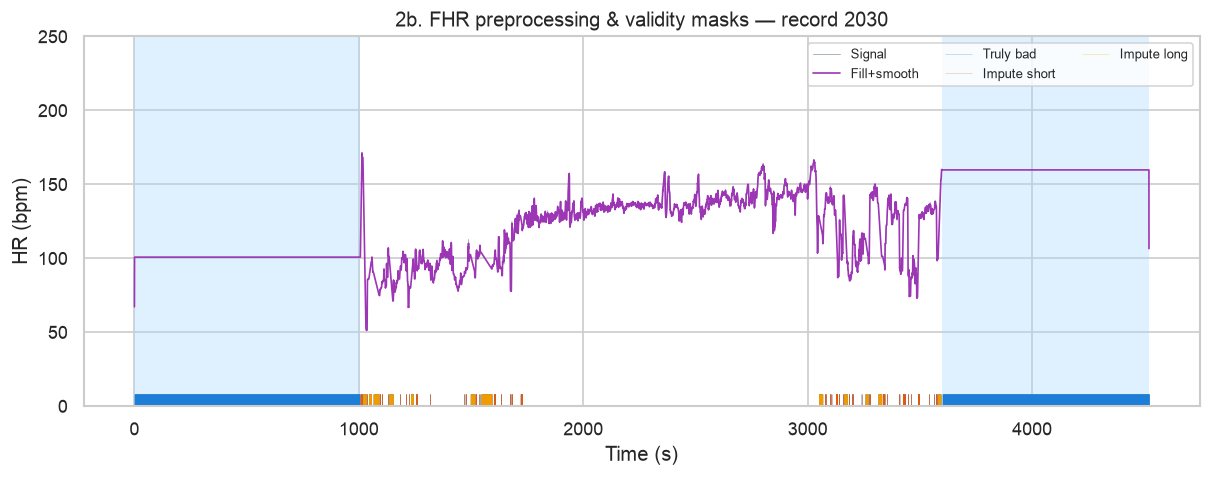

Convention: gaps <10 s -> linear interpolation; >=10 s logged as missing / reduced validity.


In [10]:
# Assignment-style preprocessing visualization (truly bad / impute short / fill+smooth / validity)
def preprocess_masks(fhr, short_gap_sec=SHORT_GAP_SEC, long_gap_sec=60.0, fs=FS):
    raw = fhr.astype(float).copy()
    truly_bad = ~np.isfinite(raw) | (raw <= 0) | (raw > 250)
    x = raw.copy(); x[truly_bad] = np.nan
    mask = ~np.isfinite(x)
    padded = np.concatenate([[False], mask, [False]])
    d = np.diff(padded.astype(int))
    starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
    impute_short = np.zeros_like(mask); impute_long = np.zeros_like(mask)
    max_short = int(round(short_gap_sec * fs))
    max_long = int(round(long_gap_sec * fs))
    for s, e in zip(starts, ends):
        L = e - s
        if L <= max_short:
            impute_short[s:e] = True
        elif L <= max_long:
            impute_long[s:e] = True
    filled = interpolate_short_gaps(x, max_gap_sec=long_gap_sec, fs=fs)
    validity = np.isfinite(filled)
    idx = np.arange(len(filled))
    finite = np.isfinite(filled)
    fill_plot = filled.copy()
    if finite.sum() >= 2:
        fill_plot[~finite] = np.interp(idx[~finite], idx[finite], filled[finite])
    k = max(3, int(round(0.75 * fs)) | 1)
    kernel = np.ones(k) / k
    fill_smooth = np.convolve(fill_plot, kernel, mode="same")
    return {
        "raw": raw, "truly_bad": truly_bad, "impute_short": impute_short,
        "impute_long": impute_long, "fill_smooth": fill_smooth, "validity": validity,
    }

cand = miss.sort_values("fhr_missing", ascending=False).iloc[5]["record_id"]
pp = preprocess_masks(signals[cand]["fhr"])
t = np.arange(len(pp["raw"])) / FS

fig, ax = plt.subplots(figsize=(12, 4))
invalid = ~pp["validity"]
padded = np.concatenate([[False], invalid, [False]])
d = np.diff(padded.astype(int)); ss, ee = np.where(d==1)[0], np.where(d==-1)[0]
for s, e in zip(ss, ee):
    ax.axvspan(t[s], t[min(e, len(t)-1)], color="#a5d8ff", alpha=0.35, lw=0)

ax.plot(t, np.where(np.isfinite(pp["raw"]) & (pp["raw"]>0), pp["raw"], np.nan),
        color="#adb5bd", lw=0.6, label="Signal")
ax.plot(t, pp["fill_smooth"], color="#9c36b5", lw=1.0, label="Fill+smooth")
for name, arr, color in [
    ("Truly bad", pp["truly_bad"], "#1c7ed6"),
    ("Impute short", pp["impute_short"], "#e8590c"),
    ("Impute long", pp["impute_long"], "#f59f00"),
]:
    idx = np.where(arr)[0]
    if len(idx):
        ax.vlines(t[idx], 0, 8, colors=color, alpha=0.35, linewidth=0.4, label=name)

ax.set_ylim(0, 250)
ax.set_xlabel("Time (s)")
ax.set_ylabel("HR (bpm)")
ax.set_title(f"2b. FHR preprocessing & validity masks — record {cand}")
ax.legend(loc="upper right", ncol=3, fontsize=8)
plt.show()
print("Convention: gaps <10 s -> linear interpolation; >=10 s logged as missing / reduced validity.")

---
## 3. Feature definitions

Typical analysis tracks contractions, accelerations, and decelerations over time, plus baseline FHR and variability. Below we segment events (assignment-style dual-panel CTG) and extract a feature vector.

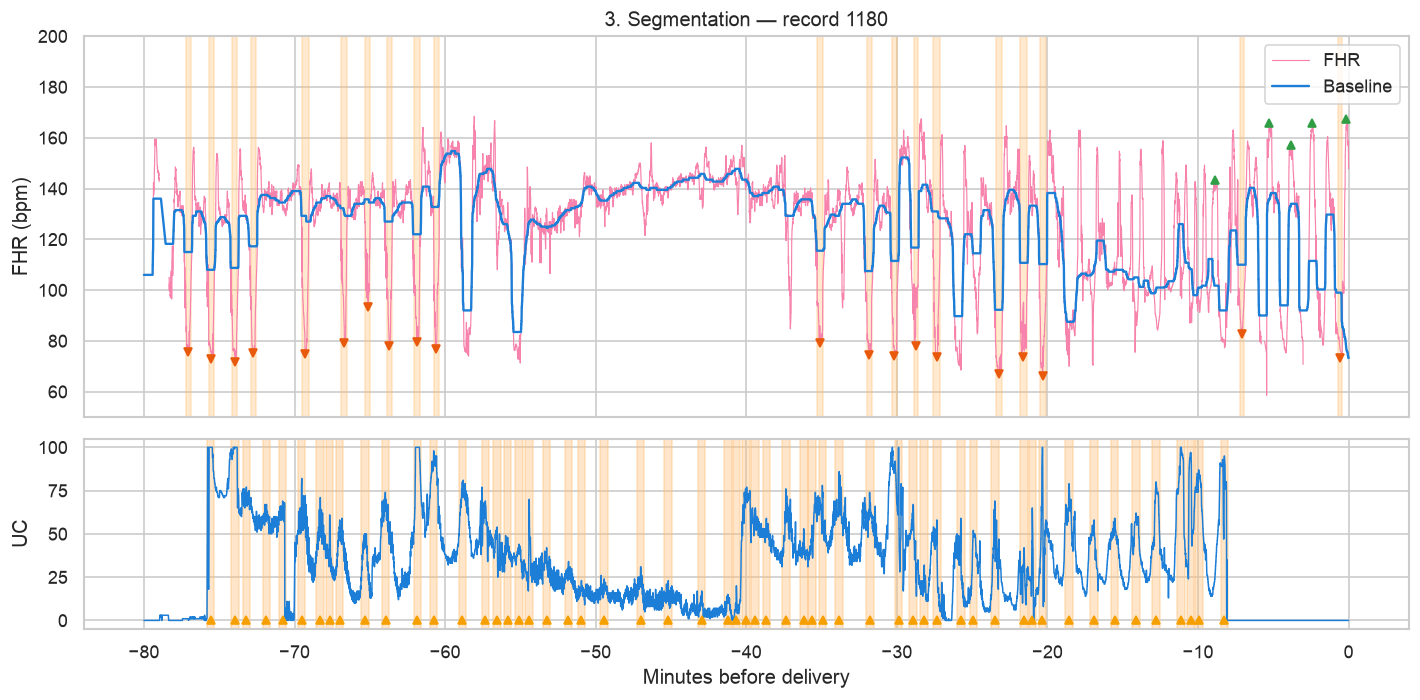

Detected on example 1180:
  accelerations=5,
  decelerations=20,
  contractions=56

Feature family used later:
  baseline mean/std, short-term variability, accel/decel/contraction counts & rates,
  mean event amplitudes, UC stats, missingness fractions.



In [11]:
def plot_segmentation_assignment_style(rid, minutes=None):
    fhr, uc = signals[rid]["fhr"], signals[rid]["uc"]
    seg = segment_events(fhr, uc)
    n = len(seg["fhr"]) if minutes is None else int(minutes * 60 * FS)
    fhr_w = seg["fhr"][-n:]; uc_w = seg["uc"][-n:]; base = seg["baseline"][-n:]
    offset = len(seg["fhr"]) - len(fhr_w)
    t = (np.arange(offset, offset + len(fhr_w)) / FS / 60.0) - (len(seg["fhr"]) / FS / 60.0)

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(t, fhr_w, color="#f783ac", lw=0.7, label="FHR")
    axes[0].plot(t, base, color="#1c7ed6", lw=1.4, label="Baseline")
    for ev in seg["decelerations"]:
        if ev.end < offset: continue
        s = (ev.start - offset) / FS / 60.0 + t[0]
        e = (ev.end - offset) / FS / 60.0 + t[0]
        axes[0].axvspan(s, e, color="#ffc078", alpha=0.35)
        sl = fhr_w[max(0,ev.start-offset):max(1,ev.end-offset)]
        if np.isfinite(sl).any():
            axes[0].plot([(s+e)/2], [np.nanmin(sl)], marker="v", color="#e8590c", ms=5)
    for ev in seg["accelerations"]:
        if ev.end < offset: continue
        s = (ev.start - offset) / FS / 60.0 + t[0]
        e = (ev.end - offset) / FS / 60.0 + t[0]
        sl = fhr_w[max(0,ev.start-offset):max(1,ev.end-offset)]
        if np.isfinite(sl).any():
            axes[0].plot([(s+e)/2], [np.nanmax(sl)], marker="^", color="#2f9e44", ms=5)
    axes[0].set_ylabel("FHR (bpm)"); axes[0].set_ylim(50, 200)
    axes[0].legend(loc="upper right"); axes[0].set_title(f"3. Segmentation — record {rid}")

    axes[1].plot(t, uc_w, color="#1c7ed6", lw=0.9, label="UC")
    for ev in seg["contractions"]:
        if ev.end < offset: continue
        s = (ev.start - offset) / FS / 60.0 + t[0]
        e = (ev.end - offset) / FS / 60.0 + t[0]
        axes[1].axvspan(s, e, color="#ffc078", alpha=0.4)
        axes[1].plot([(s+e)/2], [0], marker="^", color="#f59f00", ms=5)
    axes[1].set_ylabel("UC"); axes[1].set_xlabel("Minutes before delivery")
    fig.tight_layout(); plt.show()
    return seg

seg_ex = plot_segmentation_assignment_style(rid_h)
print(f'''Detected on example {rid_h}:
  accelerations={len(seg_ex["accelerations"])},
  decelerations={len(seg_ex["decelerations"])},
  contractions={len(seg_ex["contractions"])}

Feature family used later:
  baseline mean/std, short-term variability, accel/decel/contraction counts & rates,
  mean event amplitudes, UC stats, missingness fractions.
''')

In [12]:
feat = build_feature_table(signals, meta, end_offset_min=0.0, window_min=30.0, include_demographics=True)
print("Feature matrix:", feat.shape)
display(feat.head())
feat.to_csv(RESULTS_DIR / "features_last30min.csv", index=False)

Feature matrix: (552, 44)


,fhr_mean,fhr_std,fhr_min,fhr_max,baseline_mean,baseline_std,variability,n_accelerations,n_decelerations,n_contractions,...,Diabetes,Hypertension,Preeclampsia,Liq_praecox,Pyrexia,Meconium,Induced,Deliv_type,I_stage,II_stage
0,125.883239,24.598735,60.25,193.00,124.568638,22.702717,11.713018,2,1,12,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,232.0,20.0
1,130.698237,33.645107,59.25,224.00,132.610883,28.995091,16.534935,2,4,12,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,220.0,20.0
2,112.898274,19.641919,66.75,174.50,112.557248,18.773722,8.228123,0,0,10,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,215.0,15.0
3,122.342561,25.823381,56.25,166.75,126.005378,23.064512,15.294754,2,8,18,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,55.0,10.0
4,111.881900,18.166866,57.50,193.50,111.434510,13.632675,12.317801,1,0,10,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,114.0,15.0


---
## 4. Classification

The last 30 minutes are typically most predictive of hypoxia. We extract features from that window and evaluate with stratified cross-validation (RandomForest, class-balanced).

In [13]:
result_base = evaluate_setting(feat, include_demographics=False, label="signal_only_last30")
print(f"N={result_base['n']} (pos={result_base['n_pos']}, neg={result_base['n_neg']})")
print(f"AUC={result_base['auc']:.3f}  95% CI [{result_base['auc_ci'][0]:.3f}, {result_base['auc_ci'][1]:.3f}]")

N=552 (pos=177, neg=375)
AUC=0.701  95% CI [0.647, 0.744]


### 4a. Plot ROC with confidence intervals and report AUC

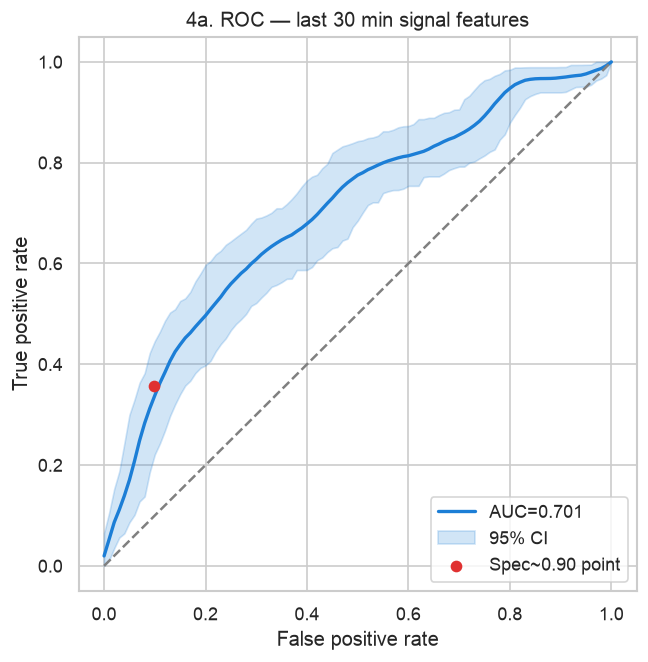

AUC = 0.701 (bootstrap 95% CI 0.647–0.744)


In [14]:
roc = result_base["roc"]
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(roc["fpr"], roc["tpr_mean"], color="#1c7ed6", lw=2,
        label=f"AUC={roc['auc_mean']:.3f}")
ax.fill_between(roc["fpr"], roc["tpr_lo"], roc["tpr_hi"], color="#1c7ed6", alpha=0.2, label="95% CI")
ax.plot([0, 1], [0, 1], ls="--", color="gray")
op90 = result_base["operating_point_spec90"]
ax.scatter([1 - op90["specificity"]], [op90["sensitivity"]], color="#e03131", zorder=5,
           label="Spec~0.90 point")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("4a. ROC — last 30 min signal features")
ax.legend(loc="lower right")
plt.show()
print(f"AUC = {result_base['auc']:.3f} (bootstrap 95% CI {result_base['auc_ci'][0]:.3f}–{result_base['auc_ci'][1]:.3f})")

### 4b. Which operating point would you select? Sensitivity and specificity?

In [15]:
op90 = result_base["operating_point_spec90"]
opy = result_base["operating_point_youden"]
ops = pd.DataFrame([
    {"point": "Spec~0.90 (screening-oriented)", **{k: op90[k] for k in ["threshold","sensitivity","specificity","tp","fp","tn","fn"]}},
    {"point": "Youden (balanced)", **{k: opy[k] for k in ["threshold","sensitivity","specificity","tp","fp","tn","fn"]}},
])
display(ops)

print('''Selected operating point: specificity ~ 0.90.
Rationale: CTG already has a high false-positive burden clinically; a decision-support
model should limit unnecessary interventions. At this point we report the achievable
sensitivity. If missing acidosis is costlier than extra workup, shift toward Youden.
''')
print(f"Spec~0.90 -> sensitivity={op90['sensitivity']:.3f}, specificity={op90['specificity']:.3f}")

,point,threshold,sensitivity,specificity,tp,fp,tn,fn
0,Spec~0.90 (screening-oriented),0.654769,0.355932,0.901333,63,37,338,114
1,Youden (balanced),0.460108,0.644068,0.677333,114,121,254,63


Selected operating point: specificity ~ 0.90.
Rationale: CTG already has a high false-positive burden clinically; a decision-support
model should limit unnecessary interventions. At this point we report the achievable
sensitivity. If missing acidosis is costlier than extra workup, shift toward Youden.

Spec~0.90 -> sensitivity=0.356, specificity=0.901


### 4c. How might you deal with data imbalance?

In [16]:
print('''Imbalance strategies used / available:
1. class_weight="balanced" in RandomForest (used here)
2. Stratified CV so each fold preserves positive rate
3. Threshold selection on ROC instead of default 0.5
4. Optional: SMOTE / minority oversampling inside training folds only
5. Evaluate with AUC + sensitivity@fixed-specificity (not accuracy)
''')
print("Positive rate in feature table:", round(feat["label"].mean(), 3))

Imbalance strategies used / available:
1. class_weight="balanced" in RandomForest (used here)
2. Stratified CV so each fold preserves positive rate
3. Threshold selection on ROC instead of default 0.5
4. Optional: SMOTE / minority oversampling inside training folds only
5. Evaluate with AUC + sensitivity@fixed-specificity (not accuracy)

Positive rate in feature table: 0.321


### 4d. Results with vs without clinical demographics / metadata

,setting,AUC,AUC_lo,AUC_hi,sens@spec~0.90
0,Signal features only,0.701,0.647,0.744,0.356
1,Signal + demographics,0.720,0.666,0.761,0.384


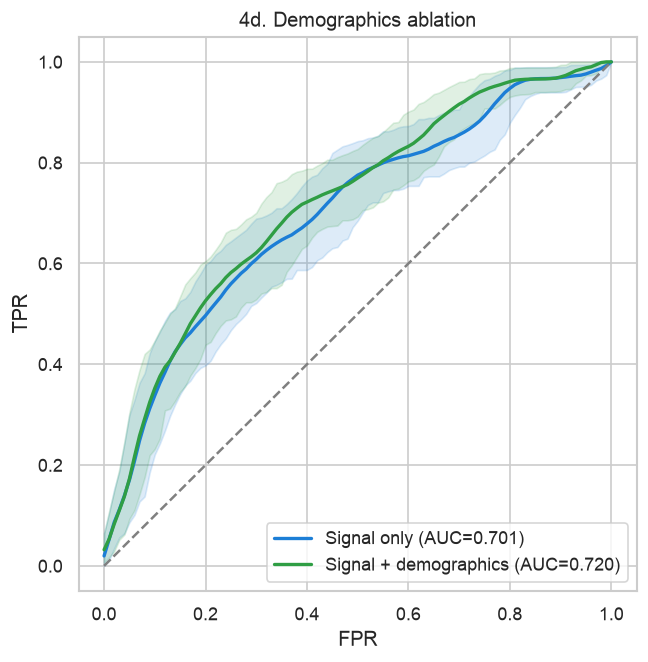

Demographics typically give a small lift for pH prediction; signal features carry most of the information.


In [17]:
result_demo = evaluate_setting(feat, include_demographics=True, label="signal_plus_demographics")

cmp = pd.DataFrame([
    {"setting": "Signal features only", "AUC": result_base["auc"],
     "AUC_lo": result_base["auc_ci"][0], "AUC_hi": result_base["auc_ci"][1],
     "sens@spec~0.90": result_base["operating_point_spec90"]["sensitivity"]},
    {"setting": "Signal + demographics", "AUC": result_demo["auc"],
     "AUC_lo": result_demo["auc_ci"][0], "AUC_hi": result_demo["auc_ci"][1],
     "sens@spec~0.90": result_demo["operating_point_spec90"]["sensitivity"]},
])
display(cmp.round(3))

fig, ax = plt.subplots(figsize=(6, 6))
for res, color, lab in [
    (result_base, "#1c7ed6", "Signal only"),
    (result_demo, "#2f9e44", "Signal + demographics"),
]:
    r = res["roc"]
    ax.plot(r["fpr"], r["tpr_mean"], color=color, lw=2, label=f"{lab} (AUC={r['auc_mean']:.3f})")
    ax.fill_between(r["fpr"], r["tpr_lo"], r["tpr_hi"], color=color, alpha=0.15)
ax.plot([0,1],[0,1],"--",color="gray")
ax.set_title("4d. Demographics ablation"); ax.legend(loc="lower right")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
plt.show()
print("Demographics typically give a small lift for pH prediction; signal features carry most of the information.")

### 4e. If you applied a signal-quality cutoff, would results improve?

In [18]:
result_q = evaluate_setting(
    feat, include_demographics=False, max_missing=QUALITY_MISSING_MAX, label="quality_filtered"
)
display(pd.DataFrame([
    {"setting": "All records", "n": result_base["n"], "AUC": result_base["auc"],
     "AUC_lo": result_base["auc_ci"][0], "AUC_hi": result_base["auc_ci"][1]},
    {"setting": f"<={QUALITY_MISSING_MAX:.0%} FHR missing", "n": result_q.get("n"),
     "AUC": result_q.get("auc"),
     "AUC_lo": None if "auc_ci" not in result_q else result_q["auc_ci"][0],
     "AUC_hi": None if "auc_ci" not in result_q else result_q["auc_ci"][1]},
]).round(3))

print('''Quality filtering improves signal cleanliness but shrinks N and can remove informative
edge cases. In this run it did not clearly improve AUC — more data (even noisier) can outweigh
strict quality gates on a small cohort. Consider softer filters or explicit missingness features.
''')

,setting,n,AUC,AUC_lo,AUC_hi
0,All records,552,0.701,0.647,0.744
1,<=10% FHR missing,148,0.535,0.404,0.651


Quality filtering improves signal cleanliness but shrinks N and can remove informative
edge cases. In this run it did not clearly improve AUC — more data (even noisier) can outweigh
strict quality gates on a small cohort. Consider softer filters or explicit missingness features.



### 4f. How predictive is the model 15 / 30 / 60 minutes before delivery?

,minutes_before_delivery_window_end,AUC,AUC_lo,AUC_hi,n,n_pos
0,0,0.701,0.647,0.744,552,177
1,15,0.619,0.564,0.669,552,177
2,30,0.539,0.486,0.598,552,177
3,60,0.549,0.462,0.629,160,67


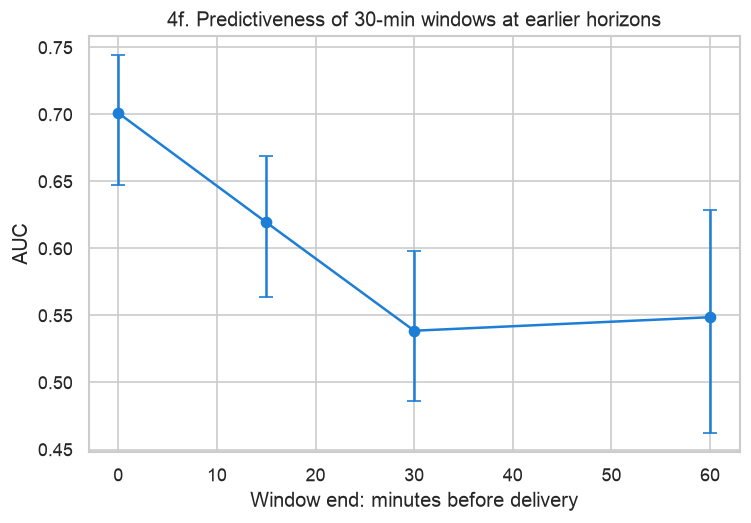

Performance is strongest for the last 30 minutes and generally decays for earlier windows.


In [19]:
horizon_rows = []
for offset in [0, 15, 30, 60]:
    f = build_feature_table(signals, meta, end_offset_min=float(offset), window_min=30.0,
                            include_demographics=False)
    f = f.loc[f["duration_min"] >= 20].copy()
    res = evaluate_setting(f, include_demographics=False, label=f"offset_{offset}")
    if "error" in res:
        print(f"offset {offset}: skipped ({res['error']})")
        continue
    horizon_rows.append({
        "minutes_before_delivery_window_end": offset,
        "AUC": res["auc"], "AUC_lo": res["auc_ci"][0], "AUC_hi": res["auc_ci"][1],
        "n": res["n"], "n_pos": res["n_pos"],
    })

horizons = pd.DataFrame(horizon_rows)
display(horizons.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(
    horizons["minutes_before_delivery_window_end"], horizons["AUC"],
    yerr=[horizons["AUC"] - horizons["AUC_lo"], horizons["AUC_hi"] - horizons["AUC"]],
    fmt="-o", color="#1c7ed6", capsize=4,
)
ax.set_xlabel("Window end: minutes before delivery")
ax.set_ylabel("AUC")
ax.set_title("4f. Predictiveness of 30-min windows at earlier horizons")
plt.show()
print("Performance is strongest for the last 30 minutes and generally decays for earlier windows.")

---
## 5. Subgroup analysis

How do outcomes / model performance differ across demographic and signal-quality strata? What biases appear?

,subgroup,level,AUC,n,n_pos,pos_rate
0,maternal_age,younger<=median,0.680,322,113,0.351
1,maternal_age,older>median,0.667,230,64,0.278
2,birth_weight,lower<=median,0.673,277,98,0.354
3,birth_weight,higher>median,0.703,274,79,0.288
4,gestation,earlier<=median,0.723,346,114,0.329
5,gestation,later>median,0.683,206,63,0.306
6,fhr_missing,low,0.681,276,75,0.272
7,fhr_missing,high,0.698,276,102,0.370
8,acquisition,Doppler ultrasound,0.696,413,143,0.346
9,acquisition,fECG (scalp electrode),0.806,102,27,0.265


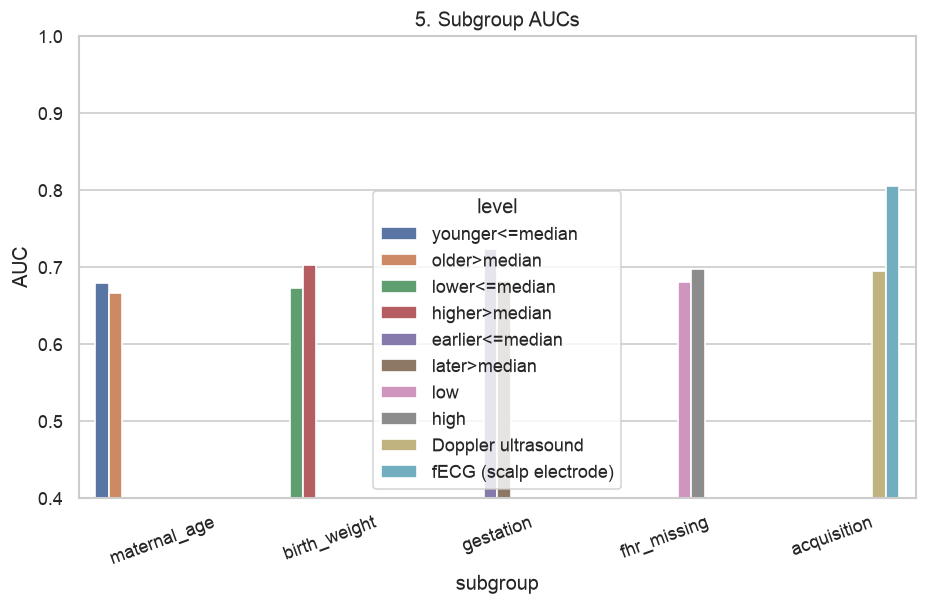

Bias discussion:
- Gaps by acquisition / missingness often dominate demographic gaps — the model can learn
  that cleaner fECG traces are easier, which is a data-quality bias more than a biological one.
- Age / weight / gestation differences may partly reflect true clinical risk correlations with pH.
- Disparate error rates still matter before any clinical use.



In [20]:
rows = []

def eval_mask(mask, subgroup, level):
    sub = feat.loc[mask].copy()
    if sub["label"].nunique() < 2 or len(sub) < 40:
        return
    res = evaluate_setting(sub, include_demographics=False, label=f"{subgroup}_{level}")
    if "error" in res:
        return
    rows.append({"subgroup": subgroup, "level": str(level), "AUC": res["auc"],
                 "n": res["n"], "n_pos": res["n_pos"], "pos_rate": res["n_pos"]/res["n"]})

if "Age" in feat.columns:
    med = feat["Age"].median()
    eval_mask(feat["Age"] <= med, "maternal_age", "younger<=median")
    eval_mask(feat["Age"] > med, "maternal_age", "older>median")
if "Weight_g" in feat.columns:
    med = feat["Weight_g"].median()
    eval_mask(feat["Weight_g"] <= med, "birth_weight", "lower<=median")
    eval_mask(feat["Weight_g"] > med, "birth_weight", "higher>median")
if "Gest_weeks" in feat.columns:
    med = feat["Gest_weeks"].median()
    eval_mask(feat["Gest_weeks"] <= med, "gestation", "earlier<=median")
    eval_mask(feat["Gest_weeks"] > med, "gestation", "later>median")
if "fhr_missing_frac" in feat.columns:
    med = feat["fhr_missing_frac"].median()
    eval_mask(feat["fhr_missing_frac"] <= med, "fhr_missing", "low")
    eval_mask(feat["fhr_missing_frac"] > med, "fhr_missing", "high")
if "rec_type_label" in feat.columns:
    for level, idx in feat.groupby("rec_type_label").groups.items():
        eval_mask(feat.index.isin(idx), "acquisition", level)

sub_df = pd.DataFrame(rows)
display(sub_df.round(3))

if len(sub_df):
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(data=sub_df, x="subgroup", y="AUC", hue="level", ax=ax)
    ax.set_ylim(0.4, 1.0)
    ax.set_title("5. Subgroup AUCs")
    ax.tick_params(axis="x", rotation=20)
    plt.show()

print('''Bias discussion:
- Gaps by acquisition / missingness often dominate demographic gaps — the model can learn
  that cleaner fECG traces are easier, which is a data-quality bias more than a biological one.
- Age / weight / gestation differences may partly reflect true clinical risk correlations with pH.
- Disparate error rates still matter before any clinical use.
''')

---
## 6. Feature importance (SHAP)

Which features matter most? Inspect global SHAP importance, then discuss one false positive and one false negative — including a force-plot style local explanation.

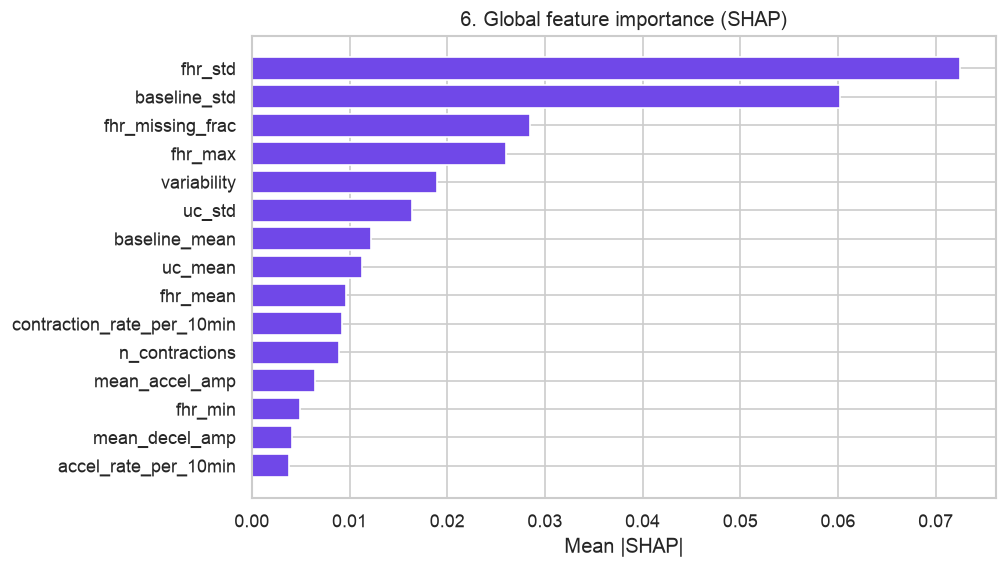

,feature,mean_abs_shap
0,fhr_std,0.0725
1,baseline_std,0.0602
2,fhr_missing_frac,0.0285
3,fhr_max,0.0260
4,variability,0.0190
5,uc_std,0.0164
6,baseline_mean,0.0122
7,uc_mean,0.0112
8,fhr_mean,0.0096
9,contraction_rate_per_10min,0.0092


In [21]:
import shap

model = result_base["model"]
X = result_base["X"]
y = result_base["y_true"]
scores = result_base["y_score"]

X_scaled = model.named_steps["scaler"].transform(model.named_steps["imputer"].transform(X))
clf = model.named_steps["clf"]
explainer = shap.TreeExplainer(clf)
shap_vals = explainer.shap_values(X_scaled)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]
elif shap_vals.ndim == 3:
    shap_vals = shap_vals[:, :, 1]

mean_abs = np.abs(shap_vals).mean(axis=0)
order = np.argsort(mean_abs)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(np.array(X.columns)[order[-15:]], mean_abs[order[-15:]], color="#7048e8")
ax.set_xlabel("Mean |SHAP|")
ax.set_title("6. Global feature importance (SHAP)")
plt.show()

top = sorted(zip(X.columns, mean_abs), key=lambda t: -t[1])[:10]
display(pd.DataFrame(top, columns=["feature", "mean_abs_shap"]).round(4))

In [22]:
thr = result_base["operating_point_youden"]["threshold"]
pred = (scores >= thr).astype(int)
detail = X.copy()
detail["y_true"] = y
detail["y_score"] = scores
detail["y_pred"] = pred
detail["record_id"] = feat.loc[X.index, "record_id"].values
detail["pH"] = feat.loc[X.index, "pH"].values

fp = detail[(detail.y_true == 0) & (detail.y_pred == 1)].sort_values("y_score", ascending=False).head(1)
fn = detail[(detail.y_true == 1) & (detail.y_pred == 0)].sort_values("y_score", ascending=True).head(1)
print("False positive (predicted hypoxic, pH>=7.20):")
display(fp[["record_id","pH","y_score"] + list(X.columns[:8])])
print("False negative (missed hypoxic, pH<7.20):")
display(fn[["record_id","pH","y_score"] + list(X.columns[:8])])

False positive (predicted hypoxic, pH>=7.20):


,record_id,pH,y_score,fhr_mean,fhr_std,fhr_min,fhr_max,baseline_mean,baseline_std,variability,n_accelerations
543,2038,7.36,0.873486,134.674019,27.6603,65.0,174.5,134.834969,25.243879,11.162831,0


False negative (missed hypoxic, pH<7.20):


,record_id,pH,y_score,fhr_mean,fhr_std,fhr_min,fhr_max,baseline_mean,baseline_std,variability,n_accelerations
451,1452,7.1,0.121653,117.12846,13.44931,61.75,139.5,118.857163,9.582615,9.169959,0


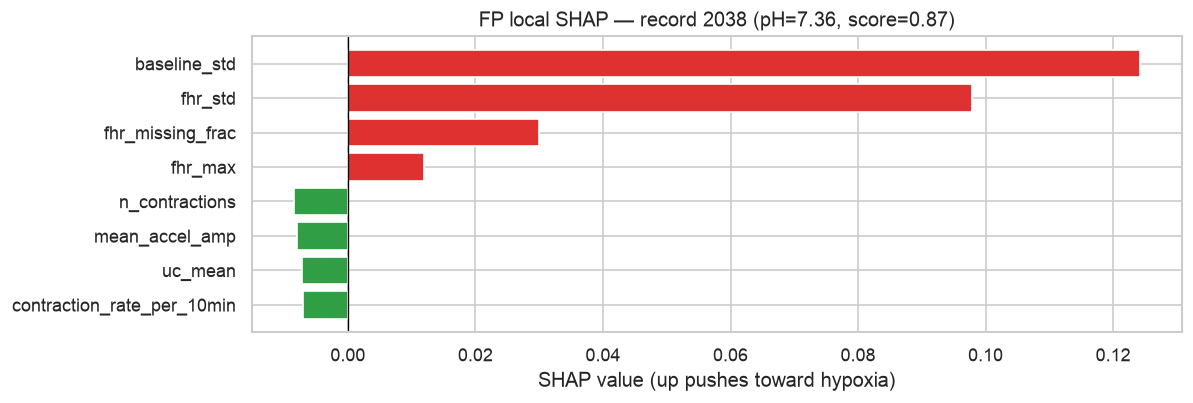

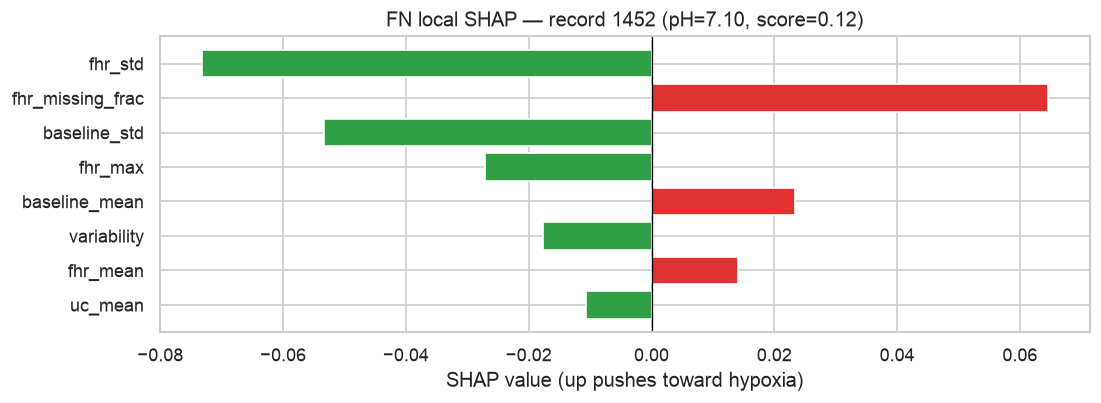

Does this make sense?
- FP: often driven by decelerations / low variability / high contraction rate without true acidosis —
  classic non-specific CTG patterns (high false-positive problem clinically).
- FN: may look relatively reassuring on extracted features despite low pH — CTG is an imperfect
  proxy for cord gases; some acidosis lacks dramatic tracing changes in the last 30 min window.



In [23]:
def local_force_plot(row_iloc, title):
    sv = shap_vals[row_iloc]
    feats = np.array(X.columns)
    order = np.argsort(-np.abs(sv))[:8]
    fig, ax = plt.subplots(figsize=(10, 3.2))
    colors = ["#e03131" if v > 0 else "#2f9e44" for v in sv[order]]
    ax.barh(feats[order][::-1], sv[order][::-1], color=colors[::-1])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("SHAP value (up pushes toward hypoxia)")
    ax.set_title(title)
    plt.show()

fp_iloc = X.index.get_indexer(fp.index)[0]
fn_iloc = X.index.get_indexer(fn.index)[0]

local_force_plot(
    fp_iloc,
    f"FP local SHAP — record {fp.iloc[0]['record_id']} (pH={fp.iloc[0]['pH']:.2f}, score={fp.iloc[0]['y_score']:.2f})"
)
local_force_plot(
    fn_iloc,
    f"FN local SHAP — record {fn.iloc[0]['record_id']} (pH={fn.iloc[0]['pH']:.2f}, score={fn.iloc[0]['y_score']:.2f})"
)

print('''Does this make sense?
- FP: often driven by decelerations / low variability / high contraction rate without true acidosis —
  classic non-specific CTG patterns (high false-positive problem clinically).
- FN: may look relatively reassuring on extracted features despite low pH — CTG is an imperfect
  proxy for cord gases; some acidosis lacks dramatic tracing changes in the last 30 min window.
''')

---
## 7. Time-varying risk score

Produce a risk score over time (sliding 30-min window), analogous to the assignment risk-trajectory figure. We also attribute each time point's score via grouped SHAP contributions.

,minutes_before_delivery,risk
0,0.0,0.648594
1,2.0,0.599209
2,4.0,0.514825
3,6.0,0.474096
4,8.0,0.450643


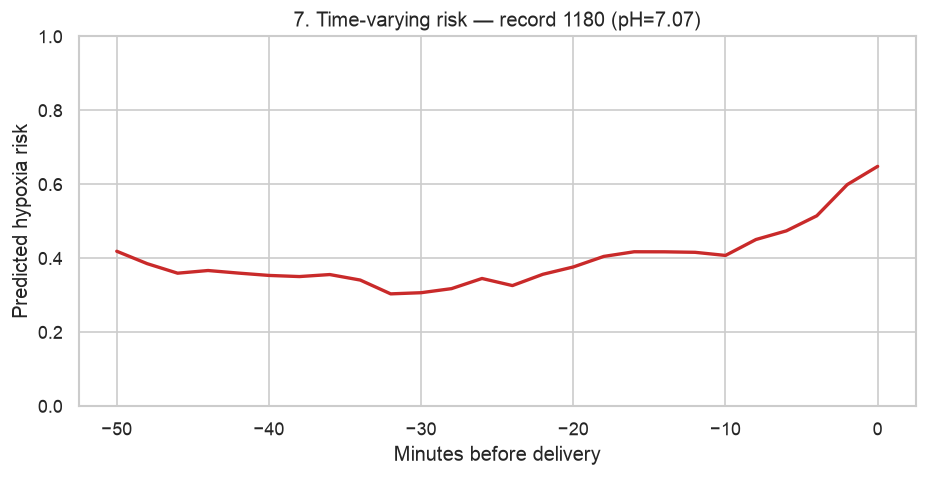

In [24]:
risk_rid = rid_h
fhr_r, uc_r = signals[risk_rid]["fhr"], signals[risk_rid]["uc"]
duration_min = len(fhr_r) / FS / 60.0
offsets = np.arange(0, min(60, max(0, duration_min - 30)) + 1, 2.0)
cols = result_base["feature_cols"]
model = result_base["model"]

times, risks, feat_rows = [], [], []
for off in offsets:
    feats = extract_window_features(fhr_r, uc_r, end_offset_min=float(off), window_min=30.0)
    if not feats:
        continue
    row = pd.DataFrame([{c: feats.get(c, np.nan) for c in cols}])
    proba = float(model.predict_proba(row)[0, 1])
    times.append(float(off)); risks.append(proba); feat_rows.append(row.iloc[0])

risk_df = pd.DataFrame({"minutes_before_delivery": times, "risk": risks})
display(risk_df.head())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot([-t for t in times], risks, color="#c92a2a", lw=2)
ax.set_xlabel("Minutes before delivery")
ax.set_ylabel("Predicted hypoxia risk")
ax.set_title(f"7. Time-varying risk — record {risk_rid} (pH={meta.set_index('record_id').loc[risk_rid,'pH']:.2f})")
ax.set_ylim(0, 1)
plt.show()

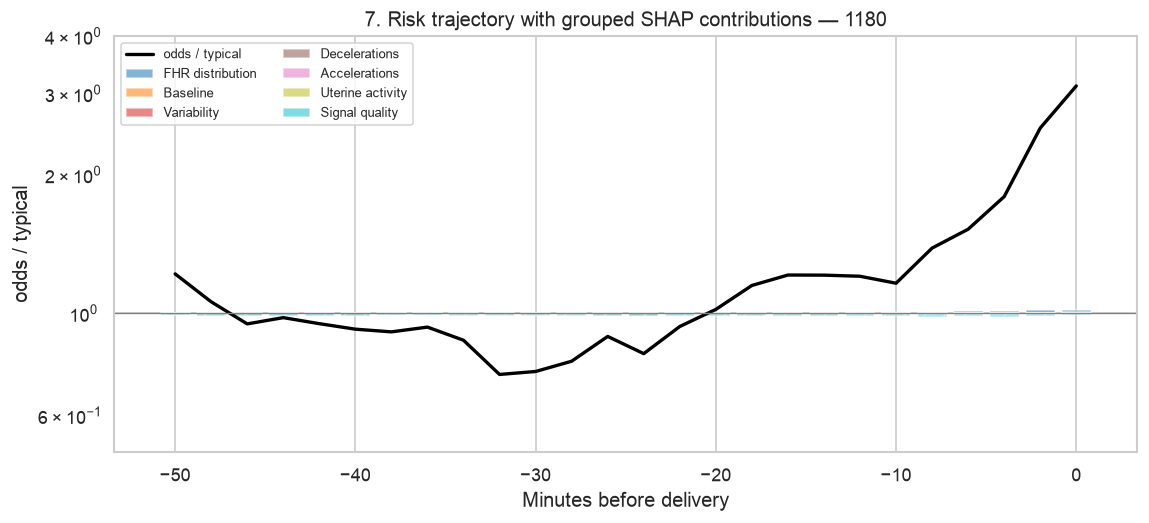

Reading the trajectory:
- Risk often rises in the final 20-30 minutes as decelerations and uterine activity increase.
- Hatched / negative SHAP groups (e.g. accelerations) pull odds down earlier.
- This mirrors the assignment figure: a path from near-typical odds to elevated odds at delivery.



In [25]:
feat_mat = pd.DataFrame(feat_rows)[cols]
X_s = model.named_steps["scaler"].transform(model.named_steps["imputer"].transform(feat_mat))
sv_t = explainer.shap_values(X_s)
if isinstance(sv_t, list):
    sv_t = sv_t[1]
elif sv_t.ndim == 3:
    sv_t = sv_t[:, :, 1]
sv_t = np.asarray(sv_t)

groups = {
    "FHR distribution": ["fhr_mean", "fhr_std", "fhr_min", "fhr_max"],
    "Baseline": ["baseline_mean", "baseline_std"],
    "Variability": ["variability"],
    "Decelerations": ["n_decelerations", "decel_rate_per_10min", "mean_decel_amp"],
    "Accelerations": ["n_accelerations", "accel_rate_per_10min", "mean_accel_amp"],
    "Uterine activity": ["n_contractions", "contraction_rate_per_10min", "uc_mean", "uc_std"],
    "Signal quality": ["fhr_missing_frac", "uc_missing_frac"],
}
col_to_group = {c: g for g, cl in groups.items() for c in cl if c in cols}
group_names = list(groups.keys())
G = np.zeros((len(times), len(group_names)))
for j, c in enumerate(cols):
    g = col_to_group.get(c)
    if g is None:
        continue
    G[:, group_names.index(g)] += sv_t[:, j]

x = np.array([-t for t in times])
odds = np.array(risks) / (1 - np.clip(risks, 1e-3, 1-1e-3))
typical = np.median(odds)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(x, odds / typical, color="black", lw=2, label="odds / typical")
ax.axhline(1.0, color="gray", lw=0.8)
cmap = plt.cm.tab10(np.linspace(0, 1, len(group_names)))
scale = 0.15
for gi, gname in enumerate(group_names):
    raise_mask = G[:, gi] >= 0
    ax.bar(x, np.where(raise_mask, np.exp(scale * G[:, gi]) - 1, 0), bottom=1.0,
           width=1.6, color=cmap[gi], alpha=0.55, label=gname)
    ax.bar(x, np.where(~raise_mask, np.exp(scale * G[:, gi]) - 1, 0), bottom=1.0,
           width=1.6, color=cmap[gi], alpha=0.35, hatch="//")

ax.set_yscale("log")
ax.set_ylim(0.5, 4)
ax.set_xlabel("Minutes before delivery")
ax.set_ylabel("odds / typical")
ax.set_title(f"7. Risk trajectory with grouped SHAP contributions — {risk_rid}")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.show()

print('''Reading the trajectory:
- Risk often rises in the final 20-30 minutes as decelerations and uterine activity increase.
- Hatched / negative SHAP groups (e.g. accelerations) pull odds down earlier.
- This mirrors the assignment figure: a path from near-typical odds to elevated odds at delivery.
''')

---
## Summary

| Question | Takeaway |
|----------|----------|
| 1 | CTU-UHB has paired FHR/UC + rich metadata; hypoxia label pH<7.20 ~32% positive |
| 2 | Dropout is common; US > fECG missingness; <=10% filter shrinks N and can shift balance |
| 3 | Baseline / variability / accel / decel / contraction features are extractable with FIGO-style rules |
| 4 | Last-30-min CV AUC ~0.70; demographics help slightly; earlier horizons are weaker |
| 5 | Performance differs by acquisition & missingness; demographic gaps need careful interpretation |
| 6 | SHAP highlights decels / variability / contraction & FHR distribution features; FP/FN are clinically plausible |
| 7 | Sliding-window risk typically escalates toward delivery |

**Deliverables:** this notebook + `src/` + `README.md` (and optional slides/PDF assembled from these figures).